In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("uber.csv")

df = df.drop(['Unnamed: 0', 'key'], axis=1)


In [2]:
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [3]:
df['dropoff_latitude'].fillna(
    value=df['dropoff_latitude'].mean(),
    inplace=True
)


C:\Users\Siddhant\AppData\Local\Temp\ipykernel_23852\1478984306.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['dropoff_latitude'].fillna(


In [4]:
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [5]:
df.pickup_datetime = pd.to_datetime(
    df.pickup_datetime,
    errors='coerce'
)


In [6]:
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00+00:00,-73.987042,40.739367,-73.986525,40.740297,1
199996,7.5,2014-03-14 01:09:00+00:00,-73.984722,40.736837,-74.006672,40.739620,1
199997,30.9,2009-06-29 00:42:00+00:00,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,2015-05-20 14:56:25+00:00,-73.997124,40.725452,-73.983215,40.695415,1


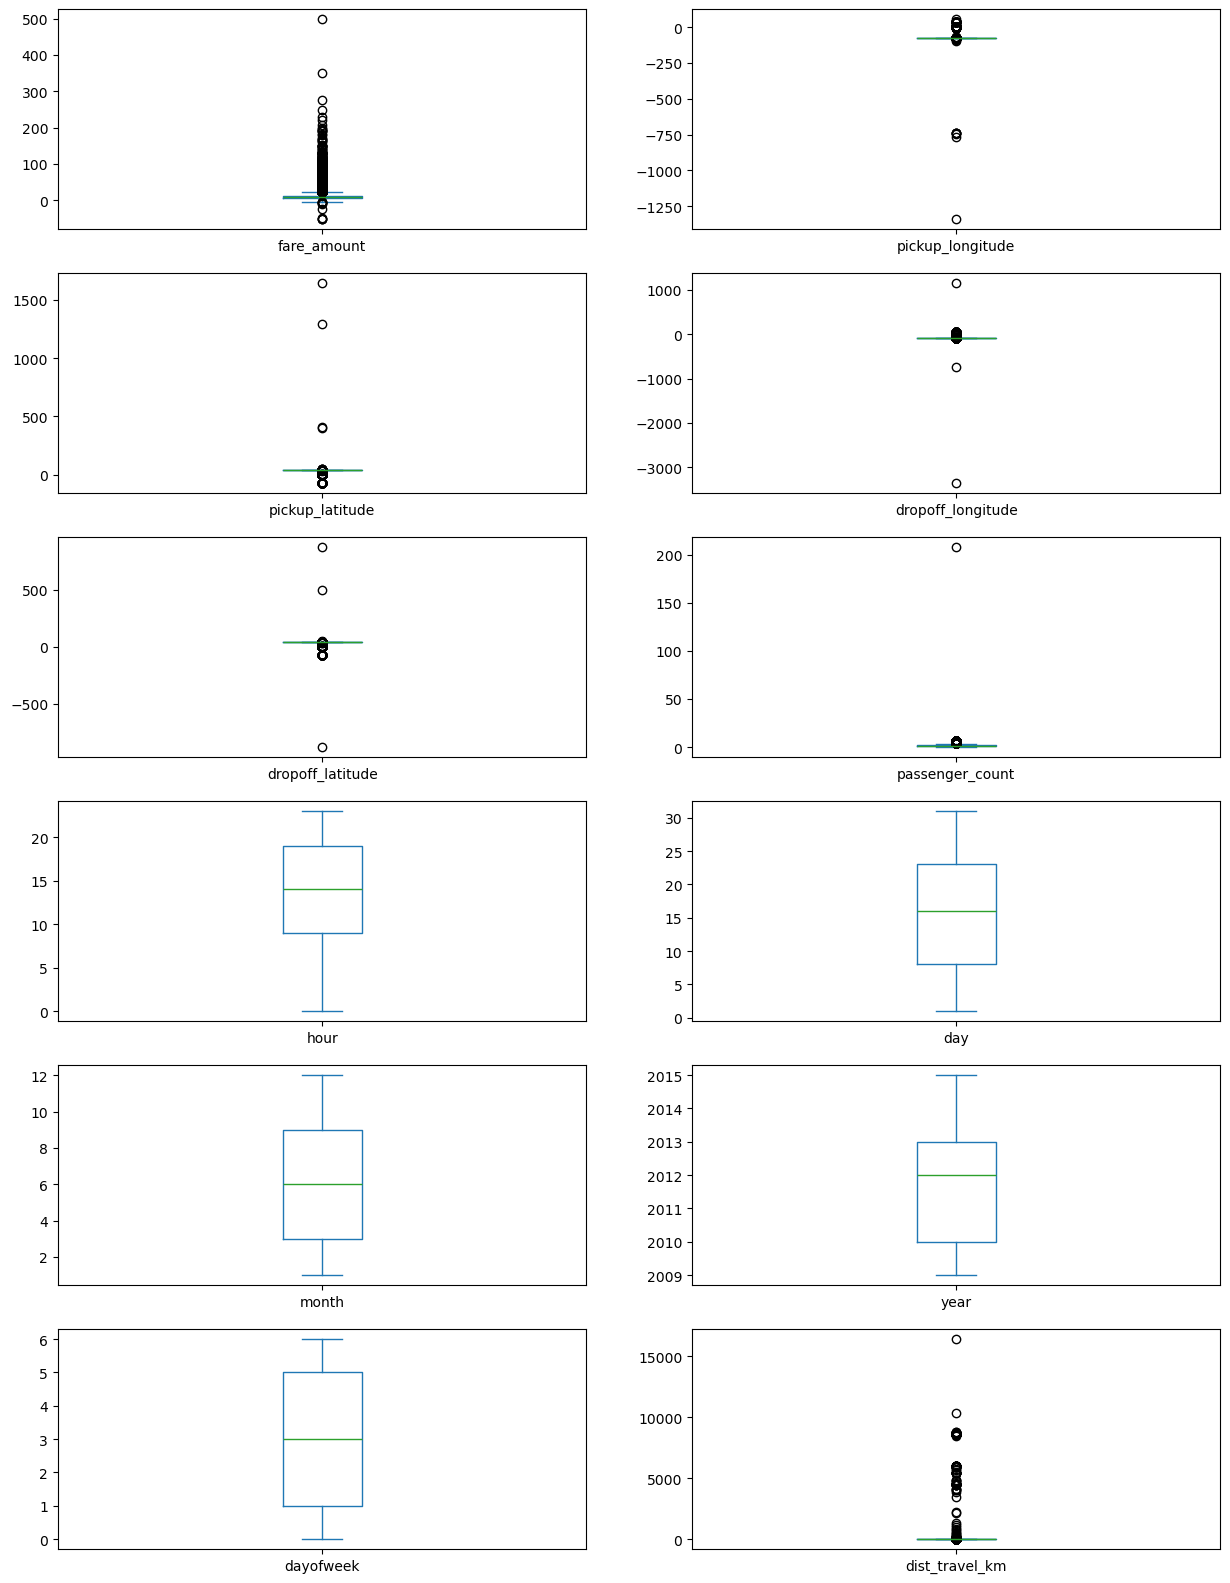

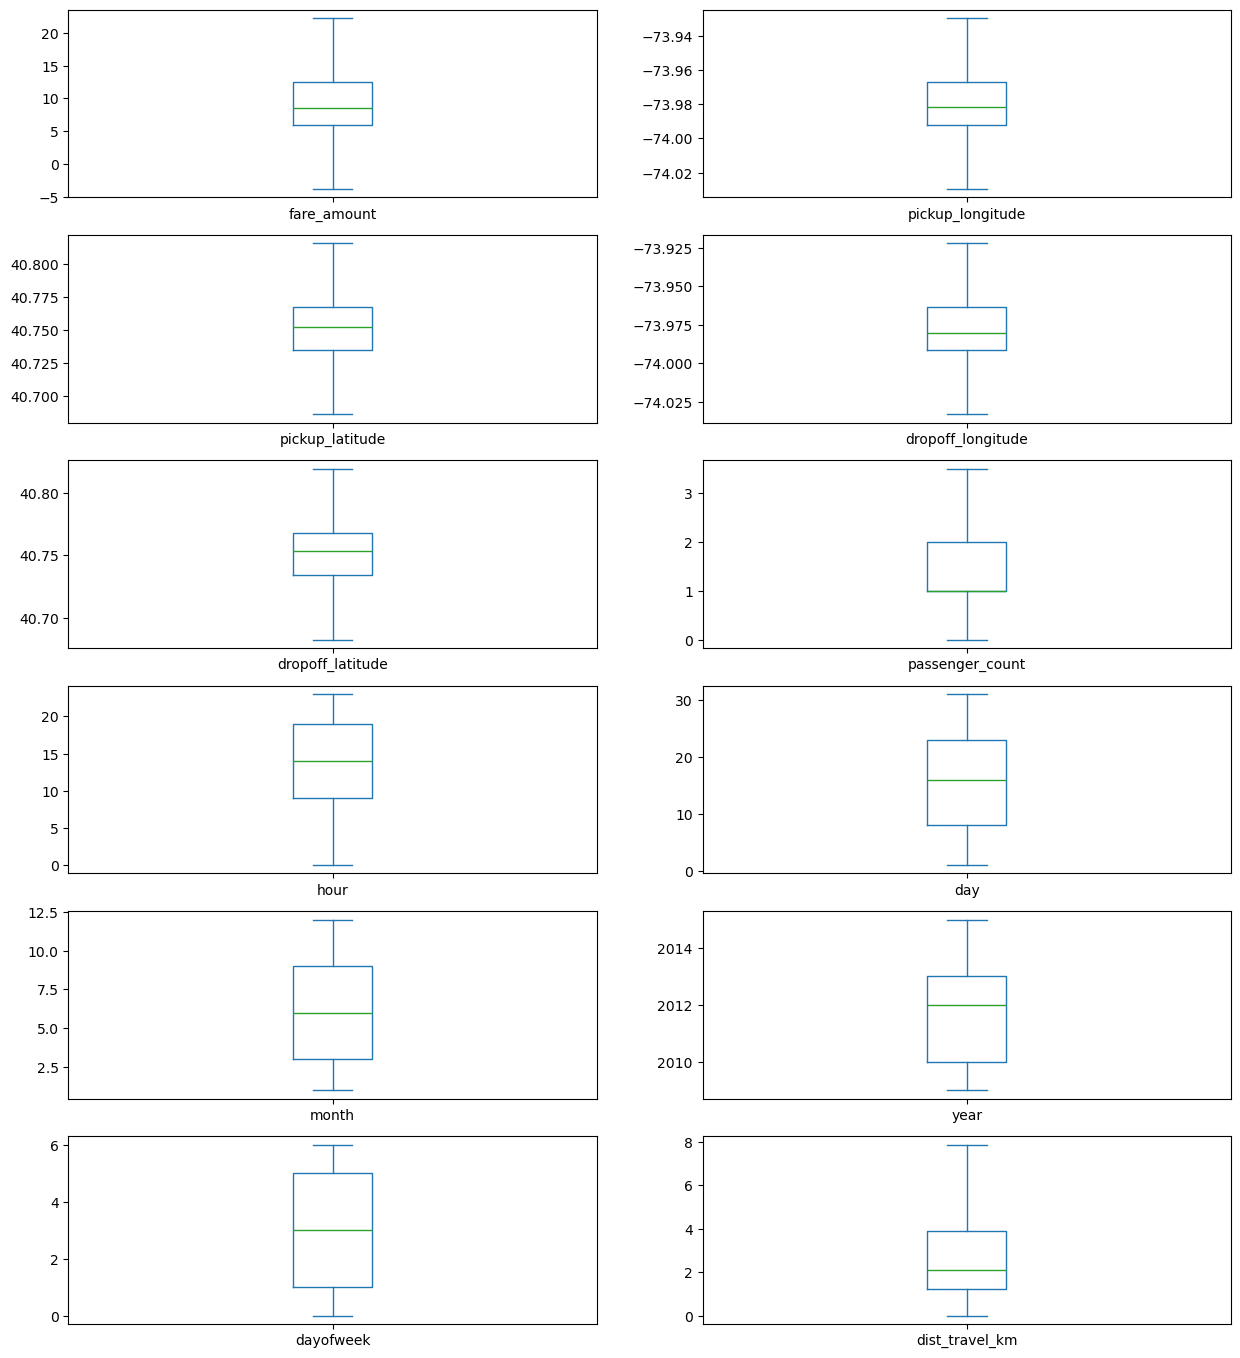

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

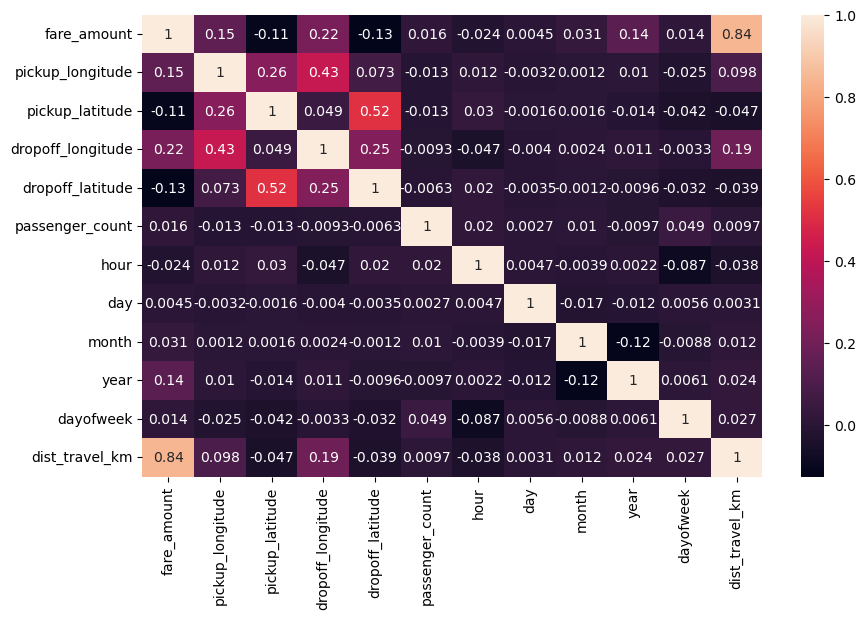

In [7]:
df = df.assign(
    hour=df.pickup_datetime.dt.hour,
    day=df.pickup_datetime.dt.day,
    month=df.pickup_datetime.dt.month,
    year=df.pickup_datetime.dt.year,
    dayofweek=df.pickup_datetime.dt.dayofweek
)

df = df.drop('pickup_datetime', axis=1)

from math import *

def distance_formula(longitude1, latitude1, longitude2, latitude2):
    travel_dist = []

    for pos in range(len(longitude1)):
        lon1, lat1, lon2, lat2 = map(
            radians,
            [
                longitude1[pos],
                latitude1[pos],
                longitude2[pos],
                latitude2[pos]
            ]
        )

        dist_lon = lon2 - lon1
        dist_lat = lat2 - lat1

        a = (
            sin(dist_lat / 2) ** 2
            + cos(lat1) * cos(lat2) * sin(dist_lon / 2) ** 2
        )

        c = 2 * asin(sqrt(a)) * 6371
        travel_dist.append(c)

    return travel_dist

df['dist_travel_km'] = distance_formula(
    df.pickup_longitude.to_numpy(),
    df.pickup_latitude.to_numpy(),
    df.dropoff_longitude.to_numpy(),
    df.dropoff_latitude.to_numpy()
)

df.plot(
    kind="box",
    subplots=True,
    layout=(6, 2),
    figsize=(15, 20)
)

plt.show()


def remove_outlier(df1, col):
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_whisker = Q1 - 1.5 * IQR
    upper_whisker = Q3 + 1.5 * IQR

    df[col] = np.clip(
        df1[col],
        lower_whisker,
        upper_whisker
    )

    return df1


def treat_outliers_all(df1, col_list):
    for c in col_list:
        df1 = remove_outlier(df, c)

    return df1


numeric_cols = df.select_dtypes(include=['number']).columns

df = treat_outliers_all(df, numeric_cols)

df.plot(
    kind="box",
    subplots=True,
    layout=(7, 2),
    figsize=(15, 20)
)

plt.show()


corr = df.corr()
corr

fig, axis = plt.subplots(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True)


x = df[
    [
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'passenger_count',
        'hour',
        'day',
        'month',
        'year',
        'dayofweek',
        'dist_travel_km'
    ]
]

y = df['fare_amount']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=1
)

from sklearn.linear_model import LinearRegression

regression = LinearRegression()

regression.fit(x_train, y_train)

regression.intercept_

regression.coef_

prediction = regression.predict(x_test)

print(prediction)

y_test

from sklearn.metrics import r2_score

r2_score(y_test, prediction)

from sklearn.metrics import mean_squared_error

MSE = mean_squared_error(y_test, prediction)

MSE

RMSE = np.sqrt(MSE)

RMSE


from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100)

rf.fit(x_train, y_train)

y_pred = rf.predict(x_test)

y_pred

R2_Random = r2_score(y_test, y_pred)

R2_Random

MSE_Random = mean_squared_error(y_test, y_pred)

MSE_Random

RMSE_Random = np.sqrt(MSE_Random)

RMSE_Random
